# Poisson Pressure Solver with Variable Density

Let $(x,y,z)\in]x_{\text{min}}, x_{\text{max}}[\times]y_{\text{min}}, y_{\text{max}}[\times]z_{\text{min}}, z_{\text{max}}]=]0, 2\pi[^3=\Omega$, 
then the Poisson's problem is defined as
\begin{equation}
    \begin{split}
        \nabla^2p(x,y,z) -\dfrac{1}{\rho(x,y,z)}\nabla\rho(x,y,z)\cdot\nabla p(x,y,z)&= 
            f(x,y,z) \quad \text{in} ~ \Omega,\\
        \frac{\partial p}{\partial z} &=0, \quad \text{on} ~ z=z_{\text{min}}, \\
        p &= 0, \quad \text{on} ~ z=z_{\text{max}},
    \end{split}
\end{equation}

with periodic boundary conditions in $x$ and $y$ directions.
The solution of this problem is
\begin{equation}
    p(x,y,z) = g(z)G(x,y,z),
\end{equation}

with

\begin{equation*}
    G(x,y,z)=\exp\left(-\left(\frac{(x - x_0)^2}{s_x} + \frac{(y - y_0)^2}{s_y}+ \frac{(z - z_0)^2}{s_z}\right)\right), \quad
    g(z) = \frac{1}{\pi^3}(2\pi z^2-z^3).
\end{equation*}

and

<!--
\begin{equation*}
    g(z) = \frac{1}{\pi^3}(2\pi z^2-z^3).
\end{equation*} 

\begin{equation}
    f(x,y,z) = \frac{1}{\pi^3}
        \left[
            \left(z^3-2\pi z^2\right)
            \left(
            \dfrac{2}{s_x}\left(1-\dfrac{2}{s_x}(x-x_0)^2\right) + 
            \dfrac{2}{s_y}\left(1-\dfrac{2}{s_y}(y-y_0)^2\right)
            \right) 
            + g(z)
        \right]
        G(x,y,z),
\end{equation}
We use $x_0=y_0=z_0=\pi$, and $s_x=s_y=s_z=.5$.
-->

In [37]:
import time as time
from fftfd import *
from ipywidgets import interact, fixed, IntSlider

In [38]:
def fftfd_density(f: np.ndarray, rho:np.ndarray, x: np.ndarray, y: np.ndarray, z: np.ndarray) -> np.ndarray:
    Nx, Ny, Nz = x.shape[0], y.shape[0], z.shape[0]
    dx, dy, dz = x[1] - x[0], y[1] - y[0], z[1] - z[0]
    x_max = x[-1] # Max x value
    y_max = y[-1] # Max y value
    p_top = np.zeros((Nx, Ny)) # Top boundary condition
    F = f[:-1, :-1, :-1] # Removing boundaries and top boundary condition
    RHO = rho[:-1, :-1] # Removing boundaries and top boundary condition
    rr = np.fft.fftfreq(Nx - 1) * (Nx - 1) 
    ss = np.fft.fftfreq(Ny - 1) * (Ny - 1) 
    # Scale frequencies for any domain
    kx = 2 * np.pi * rr * 1j / x_max
    ky = 2 * np.pi * ss * 1j / y_max
    # Compute FFT in x direction (column-wise)
    F_k = np.fft.fft2(F, axes=(0, 1))
    P_k = np.zeros_like(F_k)
    # Compute gradient of density
    # rho_x = np.gradient(rho, dx, axis=0, edge_order=2)
    # rho_y = np.gradient(rho, dy, axis=1, edge_order=2)
    # # rho_z = np.gradient(rho, dz, axis=2, edge_order=2)
    # # rho_z = np.gradient(rho, 1, axis=2, edge_order=2)
    # rho_z = np.roll(rho, -1, axis=2) - np.roll(rho, 1, axis=2)
    # Remove boundaries and top boundary
    # rho_bk = rho
    # rho = rho[:,:, 1:-1]
    # rho_x = rho_x[:,:,1:-1]
    # rho_y = rho_y[:,:,1:-1]
    # rho_z = rho_z[:,:,1:-1]
    # Compute FFT in the last row (top boundary condition)
    P_kNz = np.fft.fft2(p_top, axes=(0, 1))
    b = np.zeros(Nz - 1, dtype=np.complex128)
    c = np.zeros(Nz - 2, dtype=np.complex128)
    rho_xd = (np.roll(RHO, -1, axis=0) - np.roll(RHO, 1, axis=0)) / (2 * dx)
    rho_yd = (np.roll(RHO, -1, axis=1) - np.roll(RHO, 1, axis=1)) / (2 * dy)
    # Solve the system for each gamma
    for r in range(Nx - 1):
        for s in range(Ny - 1):
            # Compute gammas
            # gamma_right = 1 / dz ** 2 - rho_z[r, s] / (2 * rho[r, s] * dz) + 0 * 1j
            # gamma_left  = 1 / dz ** 2 + rho_z[r, s] / (2 * rho[r, s] * dz) + 0 * 1j
            # gamma_rs = kx[r] ** 2 + ky[s] ** 2 - 2 / dz ** 2 - (kx[r] * rho_x[r, s] + ky[s] * rho_y[r, s]) / rho[r, s]
            gamma_right = 1 - (RHO[r, s, 2:] - RHO[r,s,:-2]) / (4 * RHO[r, s, 1:-1]) + 0 * 1j
            gamma_left  = 1 + (RHO[r, s, 2:] - RHO[r,s,:-2]) / (4 * RHO[r, s, 1:-1]) + 0 * 1j
            # gamma_rs = (kx[r]*dz) ** 2 + (ky[s]*dz) ** 2 - 2  - dz ** 2 * (kx[r] * rho_xd[r,s, 1:-1] + ky[s] * rho_yd[r, s, 1:-1]) / RHO[r, s, 1:-1]
            gamma_rs = (kx[r]*dz) ** 2 + (ky[s]*dz) ** 2 - 2  - dz ** 2 * (kx[r] * (RHO[(r+1)%(Nx-2),s, 1:-1]-RHO[r-1,s, 1:-1])/ (2*dx) + ky[s] * (RHO[r,(s+1)%(Ny-2),1:-1]-RHO[r,s-1,1:-1])/(2*dy)) / RHO[r, s, 1:-1]
            # # Create RHS of system
            # F_k[r, s, 0] = dz * 0 + 0.5 * F_k[r, s, 1] / gamma_right[0] # dp/dz = 0
            # # Substract coefficient of top boundary condition
            # F_k[r, s, -1] -=  P_kNz[r, s] * gamma_right[-1]
            # Create RHS of system
            F_k[r, s, 0] = dz * 0 + 0.5 * dz ** 2 * F_k[r, s, 1] / gamma_right[0] # dp/dz = 0
            # Substract coefficient of top boundary condition
            F_k[r, s, -1] = dz ** 2 * F_k[r, s, -1] -  P_kNz[r, s] * gamma_right[-1]
            F_k[r, s, 1:-1] = dz ** 2 * F_k[r, s, 1:-1]
            # Create A in the system. Only keep diagonals of matrix
            a = gamma_left
            b[1:] = gamma_rs
            c[1:] = gamma_right[:-1]
            # Fix first coefficients
            # b[0] = 0.5 * gamma_left[0] / gamma_right[0] - 1.5
            b[0] = 0.5 * (4 * RHO[r, s, 1] + RHO[r, s, 2] - RHO[r, s, 0]) / (4 * RHO[r, s, 1] + RHO[r, s, 0] - RHO[r, s, 2]) - 1.5
            num = 4 * RHO[r, s, 1] * ((kx[r]*dz) ** 2 + (ky[s]*dz) ** 2 - 2) - 4 * dz ** 2 * (kx[r] * (RHO[(r+1)%(Nx-2),s, 1]-RHO[r-1,s, 1])/ (2*dx) + ky[s] * (RHO[r,(s+1)%(Ny-2),1]-RHO[r,s-1,1])/(2*dy))
            den = 4 * RHO[r, s, 1] + RHO[r, s, 0] - RHO[r, s, 2]
            tmp = num / den
            c[0] = 2 + 0.5 * tmp # gamma_rs[0] / gamma_right[0]
            # Solve system A P_k = F_k
            P_k[r, s, :] = thomas_algorithm(a, b, c, F_k[r, s, :])
    # Compute IFFT in x-y slices to restore the 'physical' pressure
    p = np.real(np.fft.ifft2(P_k, axes=(0, 1)))
    # Add x boundary condition
    p = np.concatenate([p, np.expand_dims(p[0], axis=0)], axis=0)
    # Add y boundary condition
    p = np.concatenate([p, np.expand_dims(p[:, 0], axis=1)], axis=1)
    # Add top boundary condition
    p = np.concatenate([p, np.expand_dims(p_top, axis=2)], axis=2)
    return p

In [39]:
x0 = y0 = z0 = np.pi 
sx = sy = sz = .5 ** .5
A = .5
x02 = y02 = z02 = np.pi - 0.1
sx2 = sy2 = sz2 = 1
A2 = 5 * A

In [40]:
# Functions
G = lambda x, y, z: np.exp(-((x - x0) ** 2 / sx ** 2 + (y - y0) ** 2 / sy ** 2 + (z - z0) ** 2 / sz ** 2)) 
Gx = lambda x, y, z: -2 * (x - x0) / sx ** 2 * G(x, y, z)
Gxx = lambda x, y, z: (4 * (x - x0) ** 2 / sx ** 4 - 2 / sx ** 2) * G(x, y, z)
Gy = lambda x, y, z: -2 * (y - y0) / sy ** 2 * G(x, y, z)
Gyy = lambda x, y, z: (4 * (y - y0) ** 2 / sy ** 4 - 2 / sy ** 2) * G(x, y, z)
Gz = lambda x, y, z: -2 * (z - z0) / sz ** 2 * G(x, y, z)
Gzz = lambda x, y, z: (4 * (z - z0) ** 2 / sz ** 4 - 2 / sz ** 2) * G(x, y, z)
G2 = lambda x, y, z: np.exp(-((x - x02) ** 2 / sx2 ** 2 + (y - y02) ** 2 / sy2 ** 2 + (z - z02) ** 2 / sz2 ** 2))
G2x = lambda x, y, z: -2 * (x - x02) / sx2 ** 2 * G2(x, y, z)
G2y = lambda x, y, z: -2 * (y - y02) / sy2 ** 2 * G2(x, y, z)
G2z = lambda x, y, z: -2 * (z - z02) / sz2 ** 2 * G2(x, y, z)
rho = lambda x, y, z: A * G(x, y, z) + 1
rhox = lambda x, y, z: A * Gx(x, y, z)
rhoy = lambda x, y, z: A * Gy(x, y, z)
rhoz = lambda x, y, z: A * Gz(x, y, z)
# rho = lambda x, y, z: 1 + x * 0
# rhox = lambda x, y, z: x * 0
# rhoy = lambda x, y, z: x * 0
# rhoz = lambda x, y, z: x * 0
g = lambda z: (2 * np.pi * z ** 2 - z ** 3) / np.pi ** 3 
gz = lambda z: (4 * np.pi * z - 3 * z ** 2) / np.pi ** 3 
gzz = lambda z: (4 * np.pi - 6 * z) / np.pi ** 3 
p = lambda x, y, z: g(z) * G(x, y, z)
px = lambda x, y, z: g(z) * Gx(x, y, z)
py = lambda x, y, z: g(z) * Gy(x, y, z)
pz = lambda x, y, z: g(z) * Gz(x, y, z) + gz(z) * G(x, y, z)
pxx = lambda x, y, z: g(z) * Gxx(x, y, z)
pyy = lambda x, y, z: g(z) * Gyy(x, y, z)
pzz = lambda x, y, z: gzz(z) * G(x, y, z) + 2 * gz(z) * Gz(x, y, z) + g(z) * Gzz(x, y, z)
f = lambda x, y, z: pxx(x, y, z) + pyy(x, y, z) + pzz(x, y, z) - (rhox(x, y, z) * px(x, y, z) + rhoy(x, y, z) * py(x, y, z) + rhoz(x, y, z) * pz(x, y, z)) / rho(x, y, z)
#f = lambda x, y, z: 2 * (z * (-3 + z  * (z / sx ** 2 + z / sy **2 + (4 * z - 3 * z0)/ sz ** 2)) + np.pi * (2 + 2 * z * (-z / sx ** 2 - z / sy ** 2 + (2 * z0 - 3*z)/ sz ** 2))) * G(x, y, z) / np.pi ** 3
# f = lambda x, y, z: pxx(x, y, z) + pyy(x, y, z) + pzz(x, y, z)
log_abs = lambda p, pa: np.log(np.abs(p - pa))

In [41]:
def experiment(Nx, Ny, Nz):
    x = np.linspace(0, 2 * np.pi, Nx)
    y = np.linspace(0, 2 * np.pi, Ny)
    z = np.linspace(0, 2 * np.pi, Nz)
    X, Y, Z = np.meshgrid(x, y, z, indexing='ij')
    P = p(X, Y, Z)
    F = f(X, Y, Z)
    RHO = rho(X, Y, Z)
    return x, y, z, P, F, RHO

In [42]:
def solve_iterative(x, y, z, p0, rho, f, tol=1e-14, max_iter=20, log=False):
    dx, dy, dz = x[1] - x[0], y[1] - y[0], z[1] - z[0]
    for m in range(1, max_iter+1):
        px = np.gradient(p0, dx, axis=0, edge_order=2)
        py = np.gradient(p0, dy, axis=1, edge_order=2)
        pz = np.gradient(p0, dz, axis=2, edge_order=2)
        rhox = np.gradient(rho, dx, axis=0, edge_order=2)
        rhoy = np.gradient(rho, dy, axis=1, edge_order=2)
        rhoz = np.gradient(rho, dz, axis=2, edge_order=2)
        f_new = f + (rhox * px + rhoy * py + rhoz * pz) / rho 
        p = fftfd(f_new, x, y, z)
        error = np.linalg.norm(p.flatten() - p0.flatten(), np.inf)
        p0 = p.copy()
        if log:
            print("m = %d, error = %.e" % (m, error))
        if error < tol:        
            break
    return p

In [43]:
N = 128
x, y, z, P, F, RHO = experiment(N, N, N)

In [44]:
# dx, dy, dz = x[1] - x[0], y[1] - y[0], z[1] - z[0]
# # P_x = np.gradient(P, dx, axis=0, edge_order=2)
# # P_y = np.gradient(P, dy, axis=1, edge_order=2)
# # P_z = np.gradient(P, dz, axis=2, edge_order=2)
# # P_xx = np.gradient(P_x, dx, axis=0, edge_order=2)
# # P_yy = np.gradient(P_y, dy, axis=1, edge_order=2)
# # P_zz = np.gradient(P_z, dz, axis=2, edge_order=2)
# # RHO_x = np.gradient(RHO, dx,    # rho = rho[:-1,:-1,1:-1]
    # rho_x = rho_x[:-1,:-1,1:-1]
    # rho_y = rho_y[:-1,:-1,1:-1]
    # rho_z = rho_z[:-1,:-1,:1:-1] axis=0, edge_order=2)
# # RHO_y = np.gradient(RHO, dy, axis=1, edge_order=2)
# # RHO_z = np.gradient(RHO, dz, axis=2, edge_order=2)
# P_x = (np.roll(P, -1, axis=0) - np.roll(P, 1, axis=0)) / (2 * dx)
# P_y = (np.roll(P, -1, axis=1) - np.roll(P, 1, axis=1)) / (2 * dy)
# P_z = (np.roll(P, -1, axis=2) - np.roll(P, 1, axis=2)) / (2 * dz)
# P_xx = (np.roll(P, -1, axis=0) - 2 * P + np.roll(P, 1, axis=0)) / dx ** 2
# P_yy = (np.roll(P, -1, axis=1) - 2 * P + np.roll(P, 1, axis=1)) / dy ** 2
# P_zz = (np.roll(P, -1, axis=2) - 2 * P + np.roll(P, 1, axis=2)) / dz ** 2
# RHO_x = (np.roll(RHO, -1, axis=0) - np.roll(RHO, 1, axis=0)) / (2 * dx)
# RHO_y = (np.roll(RHO, -1, axis=1) - np.roll(RHO, 1, axis=1)) / (2 * dy)
# RHO_z = (np.roll(RHO, -1, axis=2) - np.roll(RHO, 1, axis=2)) / (2 * dz)
# LHS = P_xx + P_yy + P_zz - (RHO_x * P_x + RHO_y * P_y + RHO_z * P_z) / RHO
# RHS = F
# print("LHS error = %.2e" % np.linalg.norm(LHS.flatten() - RHS.flatten(), np.inf))

In [45]:
# dx, dy, dz = x[1] - x[0], y[1] - y[0], z[1] - z[0]
# RHO_x = np.gradient(RHO, dx, axis=0, edge_order=2)
# RHO_y = np.gradient(RHO, dy, axis=1, edge_order=2)
# RHO_z = np.gradient(RHO, dz, axis=2, edge_order=2)
# plt.hist(RHO.flatten(), bins=100)
# plt.hist(RHO_x.flatten(), bins=100, alpha=0.75)
# plt.hist(RHO_y.flatten(), bins=100, alpha=0.5)
# plt.hist(RHO_z.flatten(), bins=100, alpha=0.25)
# plt.yscale('log')
# plt.show()

### Direct Method

In [46]:
# P_old = fftfd(F, x, y, z)
# error = np.linalg.norm(P_a.flatten() - P.flatten(), np.inf)
# error_base = np.linalg.norm(P_base.flatten() - P.flatten(), np.inf)
# print(error, error_base)
# plot(x, y, z, P*0 + P_a*1)

In [47]:
P_a = fftfd_density(F, RHO, x, y, z)

In [48]:
# r, s = 1,2
# plt.hist(np.real(asd[r, s]).flatten(), label=r'$\Re(asd)$')
# plt.hist(np.imag(asd[r, s]).flatten(), label=r'$\Im(asd)$', alpha=.5)
# plt.hist(np.real(asd2[r, s]).flatten(), label=r'$\Re(asd2)$', alpha=.5)
# plt.hist(np.imag(asd2[r, s]).flatten(), label=r'$\Im(asd2)$', alpha=.5)
# plt.legend()
# # plt.yscale('log')
# plt.show()

In [49]:
P_old = fftfd(F, x, y, z)

In [50]:
np.linalg.norm(P_a.flatten() - P.flatten(), np.inf), np.linalg.norm(P_old.flatten() - P.flatten(), np.inf)

(0.2623431019540958, 0.2623431019541038)

In [15]:
i_slider = IntSlider(min=0, max=x.shape[0]-1, step=1, value=x.shape[0] // 2)
j_slider = IntSlider(min=0, max=y.shape[0]-1, step=1, value=y.shape[0] // 2)
k_slider = IntSlider(min=0, max=z.shape[0]-1, step=1, value=z.shape[0] // 2)

In [16]:
interact(plot, x=fixed(x), y=fixed(y), z=fixed(z), f=fixed(log_abs(P_a, P)), title=fixed(None), i=i_slider, j=j_slider, k=k_slider)

interactive(children=(IntSlider(value=64, description='i', max=127), IntSlider(value=64, description='j', max=…

<function fftfd.plot(x: numpy.ndarray, y: numpy.ndarray, z: numpy.ndarray, f: numpy.ndarray, title: str = None, i: int = None, j: int = None, k: int = None) -> None>

In [17]:
np.linalg.norm(P_a[:, 64, :] - P[:, 64, :], np.inf)

19.73558205635912

### Iterative method

In [18]:
P_a_iter = solve_iterative(x, y, z, np.zeros_like(P), RHO, F, tol=1e-16, max_iter=13, log=True)

m = 1, error = 1e+00
m = 2, error = 3e-01
m = 3, error = 4e-02
m = 4, error = 3e-03
m = 5, error = 3e-04
m = 6, error = 2e-05
m = 7, error = 9e-07
m = 8, error = 4e-08
m = 9, error = 2e-09
m = 10, error = 7e-11
m = 11, error = 3e-12
m = 12, error = 9e-14
m = 13, error = 3e-15


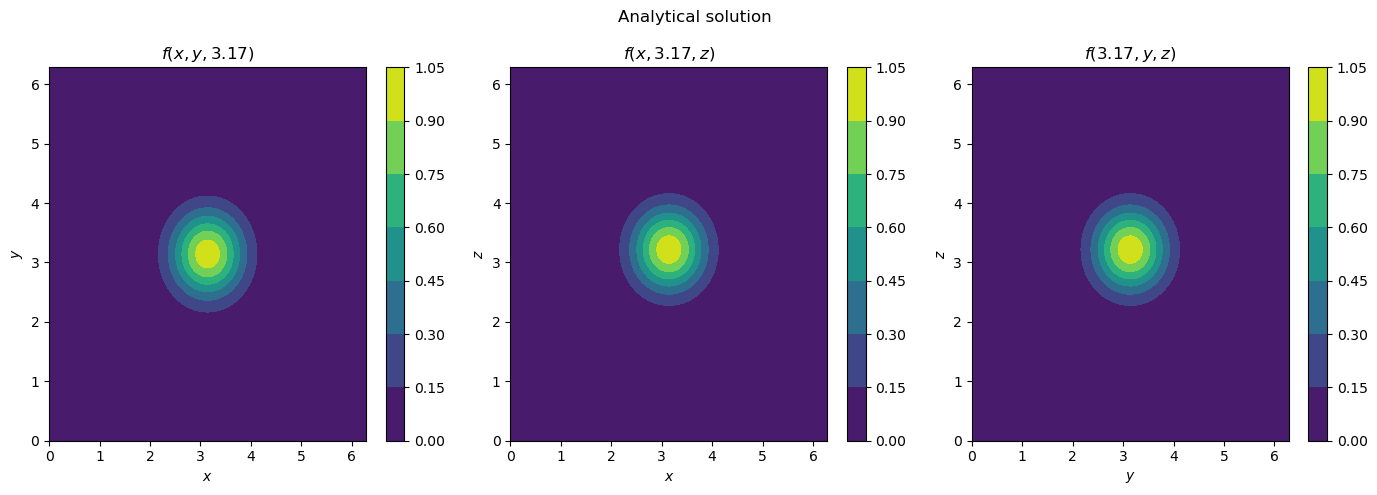

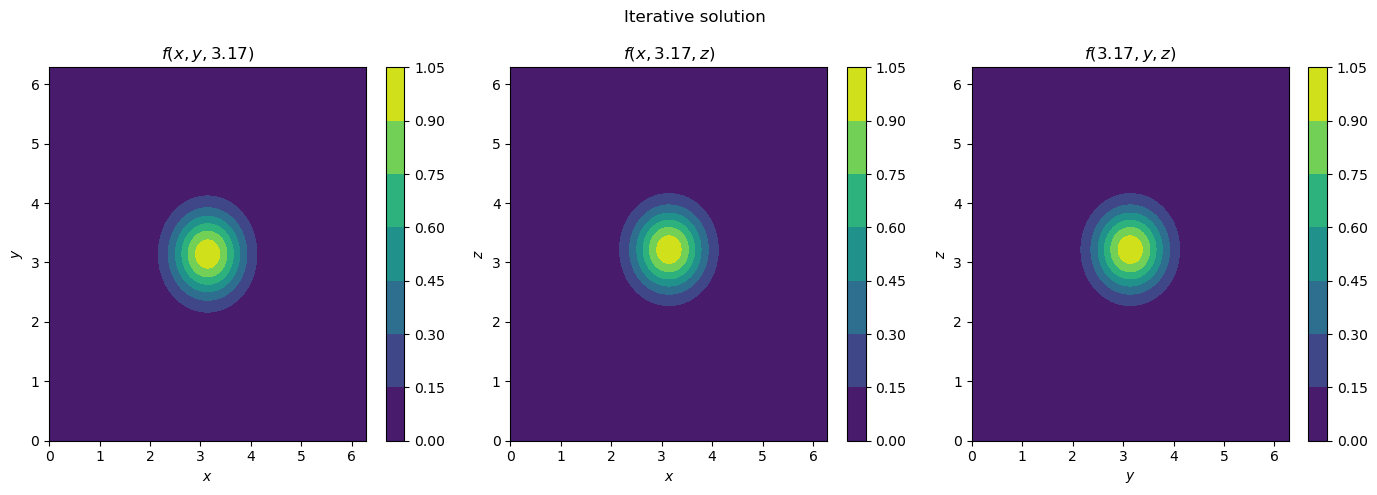

Iterative error = 2e-03


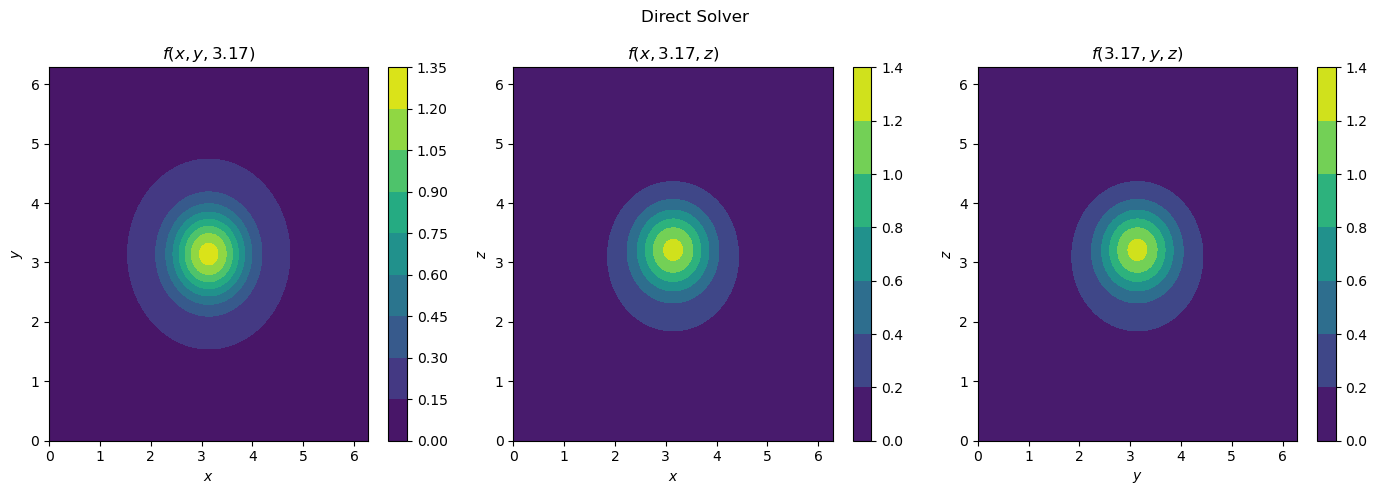

Direct error = 3e-01


In [19]:
plot(x, y, z, P, title="Analytical solution")
plot(x, y, z, P_a_iter, title="Iterative solution")
print("Iterative error = %.e" % np.linalg.norm(P.flatten() - P_a_iter.flatten(), np.inf))
plot(x, y, z, P_a, title="Direct Solver")
print("Direct error = %.e" % np.linalg.norm(P.flatten() - P_a.flatten(), np.inf))

In [20]:
np.argwhere(np.abs(P- P_a) == np.abs(P- P_a).max())

array([[63, 64, 59],
       [64, 63, 59],
       [64, 64, 59]])

0.2623431019540958


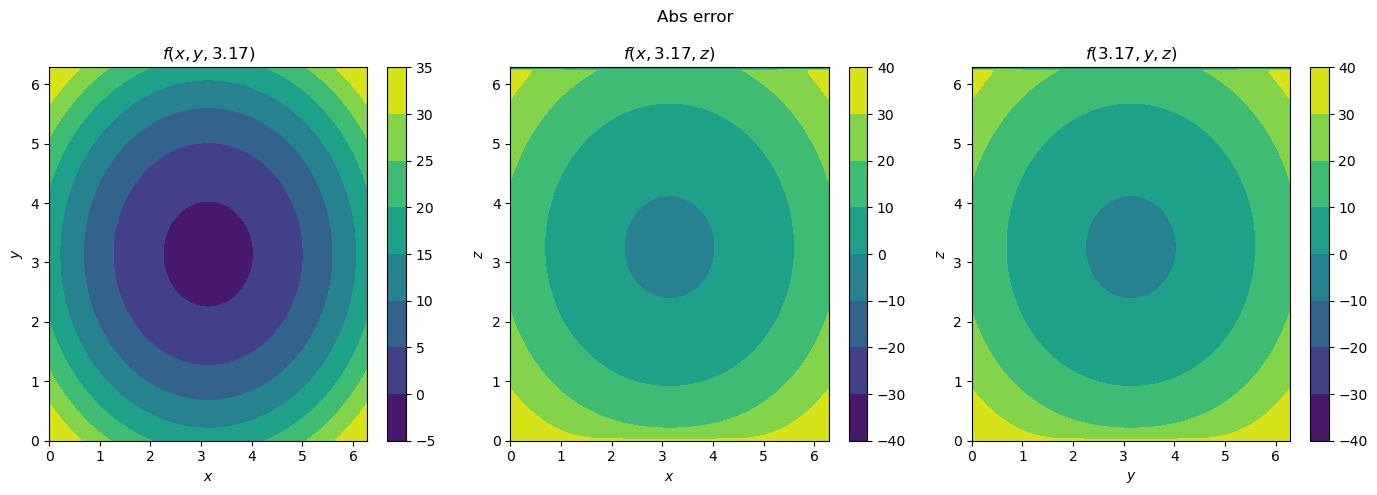

In [21]:
error = np.linalg.norm(P_a.flatten() - P.flatten(), np.inf)
print(error)
plot(x, y, z, np.log(np.abs(P - P_old)/np.abs(P+1e-16)+1e-16), title="Abs error")

In [22]:
Ns = np.array([16, 32, 64, 128, 256])
errors = np.zeros(len(Ns))
times = np.zeros(len(Ns))
dzs = np.zeros(len(Ns))
N_exp = 3
for i in range(len(Ns)):
    N = Ns[i]
    print("Computing for N =", N)
    x, y, z, P, F, RHO = experiment(N, N, N)
    start = time.time()
    for e in range(N_exp):
        # P_a = fftfd(F, x, y, z)
        P_a = solve_iterative(x, y, z, np.zeros_like(P), RHO, F, log=True)
    end = time.time()
    dzs[i] = z[1] - z[0]    
    errors[i] = np.linalg.norm(P.flatten() - P_a.flatten()) / np.linalg.norm(P.flatten())
    times[i] = (end - start) / N_exp

Computing for N = 16
m = 1, error = 1e+00
m = 2, error = 2e-01
m = 3, error = 2e-02
m = 4, error = 2e-03
m = 5, error = 1e-04
m = 6, error = 6e-06
m = 7, error = 4e-07
m = 8, error = 2e-08
m = 9, error = 1e-09
m = 10, error = 7e-11
m = 11, error = 4e-12
m = 12, error = 2e-13
m = 13, error = 1e-14
m = 14, error = 1e-15
m = 1, error = 1e+00
m = 2, error = 2e-01
m = 3, error = 2e-02
m = 4, error = 2e-03
m = 5, error = 1e-04
m = 6, error = 6e-06
m = 7, error = 4e-07
m = 8, error = 2e-08
m = 9, error = 1e-09
m = 10, error = 7e-11
m = 11, error = 4e-12
m = 12, error = 2e-13
m = 13, error = 1e-14
m = 14, error = 1e-15
m = 1, error = 1e+00
m = 2, error = 2e-01
m = 3, error = 2e-02
m = 4, error = 2e-03
m = 5, error = 1e-04
m = 6, error = 6e-06
m = 7, error = 4e-07
m = 8, error = 2e-08
m = 9, error = 1e-09
m = 10, error = 7e-11
m = 11, error = 4e-12
m = 12, error = 2e-13
m = 13, error = 1e-14
m = 14, error = 1e-15
Computing for N = 32
m = 1, error = 1e+00
m = 2, error = 3e-01
m = 3, error = 3e-0

[]

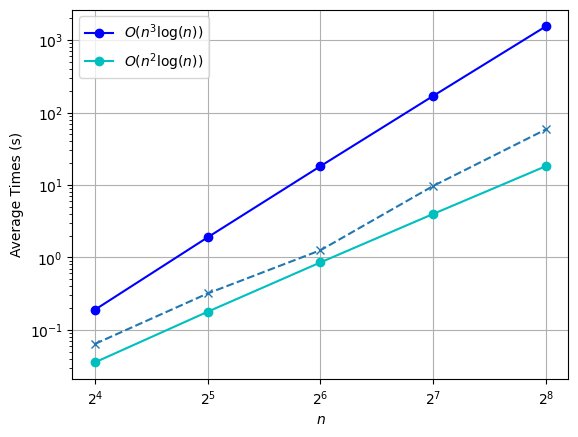

In [25]:
plt.plot(Ns, times, 'x--')
plt.plot(Ns, Ns ** 3 * np.log(Ns) / 6e4, 'b-o', label=r'$O(n^3 \log(n))$')
plt.plot(Ns, Ns ** 2 * np.log(Ns) / 2e4, 'c-o', label=r'$O(n^2 \log(n))$')
plt.grid(True)
plt.yscale('log')
plt.xlabel(r'$n$')
plt.ylabel('Average Times (s)')
plt.xscale('log', base=2)
plt.legend()
plt.plot()

[]

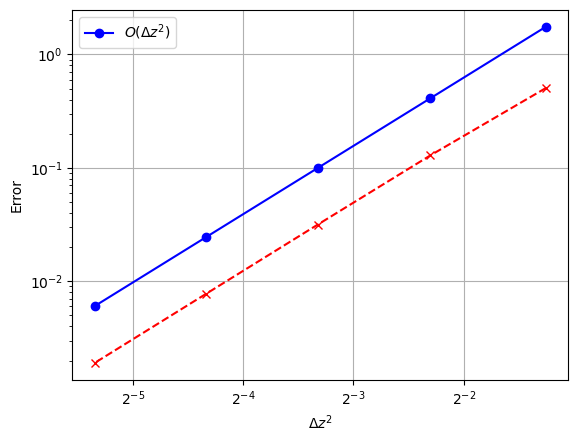

In [26]:
plt.plot(dzs, errors, 'x--r')
plt.plot(dzs, 10 * dzs ** 2, 'b-o', label=r'$O(\Delta z^2)$')
plt.grid(True)
plt.yscale('log')
plt.xlabel(r'$\Delta z^2$')
plt.ylabel('Error')
plt.xscale('log', base=2)
plt.legend()
plt.plot()

For the presentation...

In [ ]:
print("$N$ & Time (s)  \\\\")
for i in range(len(Ns)):
    print("%d & $%.2f$ \\\\" % (Ns[i], times[i]))

print("N Time")
for i in range(len(Ns)):
    print("%d  %.6f" % (Ns[i], times[i]))

In [ ]:
print("$\Delta z$ & Error  \\\\")
for i in range(len(Ns)):
    print("$%.2f$ & $%.8f$ \\\\" % (dzs[i], errors[i]))
print("dz Error")
for i in range(len(Ns)):
    print("%.8f  %.8f" % (dzs[i], errors[i]))

---